## 1 · Import Required Libraries

In [5]:
# ============================================================
# 1 · Imports
# ============================================================

import os
import glob
import math
import warnings
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from IPython.display import display, clear_output
import ipywidgets as widgets

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.cmap"] = "viridis"

## 2 · Configuration & Path Setup

In [69]:
# ============================================================
# 2 · Configuration & Path Setup
# ============================================================

# One entry per model
H5_DIRS = {
    "test_gen_data_meric_1500_13606074": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13606074/20260327_133317/metric_eval_data/test"
    ),
    "test_gen_data_meric_13600264": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test"
    ),
    "test_gen_data_meric_1500_13603608_LR_load_model40000": (
        "/mnt/c/Users/uik04723/Repositories/gen_data_metric"
        "/test_gen_data_meric_1500_13603608/20260327_012815/metric_eval_data/test"
    ),
}

# Model used in the interactive browser / single-image cells
ACTIVE_MODEL = "test_gen_data_meric_13600264"

H5_DIR = H5_DIRS[ACTIVE_MODEL]
assert os.path.isdir(H5_DIR), f"H5 directory not found: {H5_DIR}"

# Display
GT_DOT_SIZE = 16

# Metric defaults
SIGMA_GRID = np.linspace(0., 60.0, 20)  # in pixels
EPS_LOG = 1e-12

# For one-sample-per-image experiments
POINT_SAMPLING_MODE = "thinning"   # "thinning" or "block_bernoulli"

# Collect h5 files
h5_files = sorted(glob.glob(os.path.join(H5_DIR, "rank*.h5")))

print(f"Active model : {ACTIVE_MODEL}")
print(f"H5_DIR       : {H5_DIR}")
print(f"Found {len(h5_files)} h5 file(s)")
for p in h5_files:
    print(" ", p)

print("\nSIGMA_GRID =", SIGMA_GRID)
print("POINT_SAMPLING_MODE =", POINT_SAMPLING_MODE)

Active model : test_gen_data_meric_13600264
H5_DIR       : /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test
Found 4 h5 file(s)
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank00.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank01.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank02.h5
  /mnt/c/Users/uik04723/Repositories/gen_data_metric/test_gen_data_meric_13600264/20260326_150824/metric_eval_data/test/rank03.h5

SIGMA_GRID = [ 0.          3.15789474  6.31578947  9.47368421 12.63157895 15.78947368
 18.94736842 22.10526316 25.26315789 28.42105263 31.57894737 34.73684211
 37.89473684 41.05263158 44.21052632 47.36842105 50.52631579 53.68421053
 56.84210526 60.        ]
POINT_SAMPLING_MODE = thi

## 3 · H5 Helper – List & Load Samples

In [50]:
SIGMA_GRID

array([  0.        ,   7.89473684,  15.78947368,  23.68421053,
        31.57894737,  39.47368421,  47.36842105,  55.26315789,
        63.15789474,  71.05263158,  78.94736842,  86.84210526,
        94.73684211, 102.63157895, 110.52631579, 118.42105263,
       126.31578947, 134.21052632, 142.10526316, 150.        ])

In [51]:
# ============================================================
# 3 · H5 Helpers
# ============================================================

def list_h5_samples(h5_paths):
    """
    Return a list of (h5_path, sample_key) across all rank files.
    Sorted globally by sample key.
    """
    entries = []
    for path in h5_paths:
        with h5py.File(path, "r") as f:
            for key in sorted(f.keys()):
                entries.append((path, key))
    return entries


def load_h5_sample(h5_path, sample_key):
    """
    Load one sample from one H5 group.

    Expected datasets:
      - img         : (H, W, 3) uint8
      - pred_lambda : (H, W) float32
      - gt_support  : (H, W) float32/binary

    Returns a dict with img, pred_lambda, gt_support, ppp, meta.
    """
    with h5py.File(h5_path, "r") as f:
        grp = f[sample_key]
        img         = grp["img"][:]
        pred_lambda = grp["pred_lambda"][:].astype(np.float64)
        gt_support  = grp["gt_support"][:].astype(np.float64)

    H, W = pred_lambda.shape
    expected_count = float(pred_lambda.sum())
    gt_count = int((gt_support > 0).sum())

    return {
        "img": img,
        "pred_lambda": pred_lambda,
        "gt_support": gt_support,
        "ppp": {
            "H": H,
            "W": W,
            "img_area": H * W,
            "expected_count": expected_count,
            "gt_count": gt_count,
            "count_error": expected_count - gt_count,
        },
        "meta": {
            "h5_file": os.path.basename(h5_path),
            "sample_key": sample_key,
            "h5_path": h5_path,
        },
    }


all_samples = list_h5_samples(h5_files)

print(f"Total samples across all rank files: {len(all_samples)}")
print("First 5 entries:")
for entry in all_samples[:5]:
    print(" ", os.path.basename(entry[0]), "/", entry[1])

Total samples across all rank files: 500
First 5 entries:
  rank00.h5 / sample_000000
  rank00.h5 / sample_000001
  rank00.h5 / sample_000002
  rank00.h5 / sample_000003
  rank00.h5 / sample_000004


# 4 Visualization helpers

In [52]:
# ============================================================
# 4 · Visualization Helpers
# ============================================================

def get_points_from_support(support):
    ys, xs = np.where(support > 0)
    return ys, xs


def show_sample_triptych(img, pred_lambda, gt_support, title_prefix=""):
    """
    Plot image, predicted lambda, and GT overlay.
    """
    H, W = pred_lambda.shape
    gt_count = int((gt_support > 0).sum())
    expected_count = float(pred_lambda.sum())

    ys, xs = get_points_from_support(gt_support)

    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    axes[0].imshow(img, aspect="auto")
    axes[0].set_title(f"{title_prefix}Image")
    axes[0].axis("off")

    im = axes[1].imshow(pred_lambda, cmap="hot", aspect="auto")
    axes[1].set_title(rf"{title_prefix}Predicted $\lambda$" + f"\nE[N]={expected_count:.2f}")
    axes[1].axis("off")
    plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

    axes[2].imshow(img, aspect="auto")
    axes[2].scatter(xs, ys, s=GT_DOT_SIZE, c="lime", linewidths=0, alpha=0.9)
    axes[2].set_title(f"{title_prefix}GT overlay\nN={gt_count}")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

# 5 — New metric helpers

In [70]:
# ============================================================
# 5 · Gaussianized PPP Score Helpers (dense + incremental)
# ============================================================
import time
import numpy as np
from scipy.ndimage import gaussian_filter

def point_cloud_to_impulse_grid(point_grid):
    x = np.asarray(point_grid, dtype=np.float64)
    return np.clip(x, 0.0, None)

def ppp_loglik_score(h, gt_support, eps=EPS_LOG):
    h = np.asarray(h, dtype=np.float64)
    gt_idx = np.asarray(gt_support) > 0
    return float(np.log(np.clip(h[gt_idx], eps, None)).sum() - h.sum())

def _mass_preserving_blur(x, sigma):
    x = np.asarray(x, dtype=np.float64)
    mass = x.sum()
    if mass <= 0:
        return np.zeros_like(x, dtype=np.float64)
    y = gaussian_filter(x / mass, sigma=float(sigma), mode="constant", cval=0.0)
    s = y.sum()
    if s > 0:
        y *= mass / s
    return y

def gaussianize_intensity(pred_lambda, sigma):
    return _mass_preserving_blur(pred_lambda, sigma)

def gaussianize_point_cloud(point_grid, sigma):
    return _mass_preserving_blur(point_cloud_to_impulse_grid(point_grid), sigma)

def _optimize_sigma_incremental(x, gt_support, sigma_grid):
    """
    Efficient optimization over sigma using Gaussian variance additivity.
    sigma_grid must be strictly increasing and nonnegative.
    """
    sigma_grid = np.asarray(sigma_grid, dtype=np.float64)
    if sigma_grid.ndim != 1 or len(sigma_grid) == 0:
        raise ValueError("sigma_grid must be a nonempty 1D array")
    if np.any(sigma_grid < 0):
        raise ValueError("sigma_grid must be nonnegative")
    if np.any(np.diff(sigma_grid) <= 0):
        raise ValueError("sigma_grid must be strictly increasing")

    x = np.asarray(x, dtype=np.float64)
    mass = x.sum()
    if mass <= 0:
        scores = np.full(len(sigma_grid), -np.inf, dtype=np.float64)
        return {
            "sigma_grid": sigma_grid,
            "scores": scores,
            "best_sigma": float(sigma_grid[0]),
            "best_score": float(scores[0]),
        }

    gt_idx = np.asarray(gt_support) > 0

    # start from sigma = sigma_grid[0]
    st = time.process_time()
    h = gaussian_filter(x / mass, sigma=float(sigma_grid[0]), mode="constant", cval=0.0)
    print(f"Initial blur with sigma={sigma_grid[0]:.2f} took {time.process_time() - st:.4f} seconds")
    s = h.sum()
    if s > 0:
        h *= mass / s

    scores = [float(np.log(np.clip(h[gt_idx], EPS_LOG, None)).sum() - h.sum())]

    prev_sigma2 = float(sigma_grid[0] ** 2)

    for sigma in sigma_grid[1:]:
        sigma2 = float(sigma ** 2)
        sigma_inc = math.sqrt(max(0.0, sigma2 - prev_sigma2))

        st = time.process_time()
        h = gaussian_filter(h, sigma=sigma_inc, mode="constant", cval=0.0)
        print(f"Incremental blur with sigma_inc={sigma_inc:.2f} (total sigma={sigma:.2f}) took {time.process_time() - st:.4f} seconds")
        s = h.sum()
        if s > 0:
            h *= mass / s

        scores.append(float(np.log(np.clip(h[gt_idx], EPS_LOG, None)).sum() - h.sum()))
        prev_sigma2 = sigma2

    scores = np.asarray(scores, dtype=np.float64)
    best_idx = int(np.argmax(scores))
    return {
        "sigma_grid": sigma_grid,
        "scores": scores,
        "best_sigma": float(sigma_grid[best_idx]),
        "best_score": float(scores[best_idx]),
    }

def optimize_sigma_for_intensity(pred_lambda, gt_support, sigma_grid=SIGMA_GRID):
    return _optimize_sigma_incremental(pred_lambda, gt_support, sigma_grid)

def optimize_sigma_for_point_cloud(point_grid, gt_support, sigma_grid=SIGMA_GRID):
    return _optimize_sigma_incremental(point_cloud_to_impulse_grid(point_grid), gt_support, sigma_grid)

# 6 · Sampling One Point-Cloud Prediction from Lambda

In [71]:
def sample_ppp_by_thinning(
    lambda_grid: np.ndarray,
    *,
    pixel_area: float | None = None,
    rng: np.random.Generator | None = None,
):
    """
    Sample an inhomogeneous PPP using thinning from a homogeneous PPP.

    Parameters
    ----------
    lambda_grid : (H, W) array
        Intensity lambda(x) per pixel (mass per pixel, non-negative).
    pixel_area : float
        Kept for API compatibility, not used.
    rng : np.random.Generator

    Returns
    -------
    points_xy  : (N, 2) array  – accepted points in image coords (x, y)
    N          : int
    lambda_max : float
    N_prop     : int           – number of proposals before thinning
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    assert np.all(lam >= 0)
    H, W = lam.shape

    lambda_max = lam.max()
    if lambda_max == 0:
        return np.zeros((0, 2)), 0, 0.0, 0

    area_total = H * W
    Lambda_hom = lambda_max * area_total
    N_prop = rng.poisson(Lambda_hom)

    if N_prop == 0:
        return np.zeros((0, 2)), 0, lambda_max, 0

    xs = rng.random(N_prop) * W
    ys = rng.random(N_prop) * H
    xi = np.clip(xs.astype(int), 0, W - 1)
    yi = np.clip(ys.astype(int), 0, H - 1)

    lam_x = lam[yi, xi]
    accept_prob = lam_x / lambda_max
    keep = rng.random(N_prop) < accept_prob

    points_xy = np.stack([xs[keep], ys[keep]], axis=1)
    return points_xy, points_xy.shape[0], float(lambda_max), N_prop


def sample_points_block_bernoulli(
    lambda_grid: np.ndarray,
    *,
    block_size: int = 8,
    pixel_area: float = 1.0,
    placement: str = "weighted",
    rng: np.random.Generator | None = None,
):
    """
    Block/Bernoulli approximation of a PPP.

    For each block A:
        Λ_A = sum_A λ * pixel_area
        Activate with p_A = 1 - exp(-Λ_A)
    If active, place exactly one point in A.

    Parameters
    ----------
    lambda_grid : (H, W) array  – intensity mass per pixel
    block_size  : int           – side length of each block in pixels
    pixel_area  : float         – set to 1.0 when lambda_grid is already mass per pixel
    placement   : "weighted" | "uniform"

    Returns
    -------
    points_xy : (N, 2) array
    stats     : dict
    """
    if rng is None:
        rng = np.random.default_rng()

    lam = np.asarray(lambda_grid, dtype=np.float64)
    if lam.ndim != 2:
        raise ValueError("lambda_grid must be 2D.")
    if not np.all(np.isfinite(lam)):
        raise ValueError("lambda_grid contains NaN/Inf.")
    if np.any(lam < 0):
        raise ValueError("lambda_grid contains negative values.")
    if placement not in {"weighted", "uniform"}:
        raise ValueError("placement must be 'weighted' or 'uniform'")

    bs = int(block_size)
    H, W = lam.shape
    nby = (H + bs - 1) // bs
    nbx = (W + bs - 1) // bs
    num_blocks = nby * nbx

    Hp, Wp = nby * bs, nbx * bs
    if Hp != H or Wp != W:
        lam_pad = np.zeros((Hp, Wp), dtype=np.float64)
        lam_pad[:H, :W] = lam
    else:
        lam_pad = lam

    lam_blocks = lam_pad.reshape(nby, bs, nbx, bs).transpose(0, 2, 1, 3)
    block_sums = lam_blocks.sum(axis=(2, 3)) * pixel_area  # (nby, nbx)

    p_active = 1.0 - np.exp(-block_sums)
    expected_blocks_active = float(p_active.sum())

    active_mask = rng.random(size=(nby, nbx)) < p_active
    active_by, active_bx = np.nonzero(active_mask)
    num_active = active_by.size

    if num_active == 0:
        return np.zeros((0, 2), dtype=np.float64), dict(
            block_size=bs, placement=placement,
            num_blocks=num_blocks, num_active_blocks=0,
            expected_active_blocks=expected_blocks_active, num_points=0,
        )

    points_xy = np.empty((num_active, 2), dtype=np.float64)
    x0s = active_bx * bs
    y0s = active_by * bs
    wBs = np.minimum(bs, W - x0s)
    hBs = np.minimum(bs, H - y0s)

    if placement == "uniform":
        points_xy[:, 0] = x0s + rng.random(num_active) * wBs
        points_xy[:, 1] = y0s + rng.random(num_active) * hBs
    else:
        for i, (by, bx, x0, y0, wB, hB) in enumerate(
            zip(active_by, active_bx, x0s, y0s, wBs, hBs)
        ):
            block = lam[y0:y0 + hB, x0:x0 + wB]
            s = block.sum()
            if s <= 0:
                points_xy[i, 0] = x0 + rng.random() * wB
                points_xy[i, 1] = y0 + rng.random() * hB
                continue
            probs = block.ravel() / s
            idx = rng.choice(probs.size, p=probs)
            py, px = divmod(idx, wB)
            points_xy[i, 0] = x0 + px + rng.random()
            points_xy[i, 1] = y0 + py + rng.random()

    return points_xy, dict(
        block_size=bs, placement=placement,
        num_blocks=num_blocks, num_active_blocks=int(num_active),
        expected_active_blocks=expected_blocks_active, num_points=int(num_active),
    )

print("Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli")


Sampling functions loaded: sample_ppp_by_thinning, sample_points_block_bernoulli


In [72]:
# ============================================================
# 6 · Sampling Wrapper (uses thinning + block Bernoulli)
# ============================================================

def point_list_to_count_grid(points_xy, shape):
    """
    Convert (x, y) point list into a count grid (H, W).
    Multiplicities are preserved.
    """
    H, W = shape
    grid = np.zeros((H, W), dtype=np.float64)

    if points_xy is None or len(points_xy) == 0:
        return grid

    points_xy = np.asarray(points_xy, dtype=np.float64)

    xs = np.floor(points_xy[:, 0]).astype(int)
    ys = np.floor(points_xy[:, 1]).astype(int)

    valid = (xs >= 0) & (xs < W) & (ys >= 0) & (ys < H)
    xs = xs[valid]
    ys = ys[valid]

    np.add.at(grid, (ys, xs), 1.0)
    return grid


def sample_point_cloud_from_lambda(
    pred_lambda,
    rng=None,
    mode="thinning",
    gt_count=None,              # kept for compatibility
    block_size=8,
    placement="weighted",
    pixel_area=1.0,
):
    """
    Unified wrapper for sampling a point cloud from a predicted intensity.

    Modes
    -----
    thinning:
        Exact PPP sampling via thinning.

    block_bernoulli:
        Block-wise Bernoulli approximation.

    Returns
    -------
    point_grid : (H, W) float64
        Count grid (multiplicities preserved).
    sampled_meta : dict
    """
    rng = np.random.default_rng() if rng is None else rng
    lam = np.asarray(pred_lambda, dtype=np.float64)

    if lam.ndim != 2:
        raise ValueError("pred_lambda must be 2D")
    if not np.all(np.isfinite(lam)):
        raise ValueError("pred_lambda contains NaN/Inf")
    if np.any(lam < 0):
        raise ValueError("pred_lambda contains negative values")

    H, W = lam.shape

    # --------------------------------------------------------
    # Thinning sampler (PPP-consistent)
    # --------------------------------------------------------
    if mode == "thinning":
        points_xy, n_points, lambda_max, n_prop = sample_ppp_by_thinning(
            lam,
            pixel_area=pixel_area,
            rng=rng,
        )

        point_grid = point_list_to_count_grid(points_xy, (H, W))

        sampled_meta = {
            "mode": "thinning",
            "num_points": int(n_points),
            "grid_count_sum": int(point_grid.sum()),
            "binary_count": int((point_grid > 0).sum()),
            "lambda_max": float(lambda_max),
            "n_proposals": int(n_prop),
            "expected_count_input": float(lam.sum()),
        }
        return point_grid, sampled_meta

    # --------------------------------------------------------
    # Block Bernoulli sampler (approximation)
    # --------------------------------------------------------
    elif mode == "block_bernoulli":
        points_xy, stats = sample_points_block_bernoulli(
            lam,
            block_size=block_size,
            pixel_area=pixel_area,
            placement=placement,
            rng=rng,
        )

        point_grid = point_list_to_count_grid(points_xy, (H, W))

        sampled_meta = {
            "mode": "block_bernoulli",
            "num_points": int(point_grid.sum()),
            "grid_count_sum": int(point_grid.sum()),
            "binary_count": int((point_grid > 0).sum()),
            "expected_count_input": float(lam.sum()),
            **stats,
        }
        return point_grid, sampled_meta

    else:
        raise ValueError("mode must be 'thinning' or 'block_bernoulli'")


print("Sampling wrapper loaded: sample_point_cloud_from_lambda (thinning + block_bernoulli)")

Sampling wrapper loaded: sample_point_cloud_from_lambda (thinning + block_bernoulli)


# 7 — Quick smoke test on first sample

Sample : rank00.h5 / sample_000000
Shape  : (544, 1792)
E[N]   : 106.852
GT N   : 67


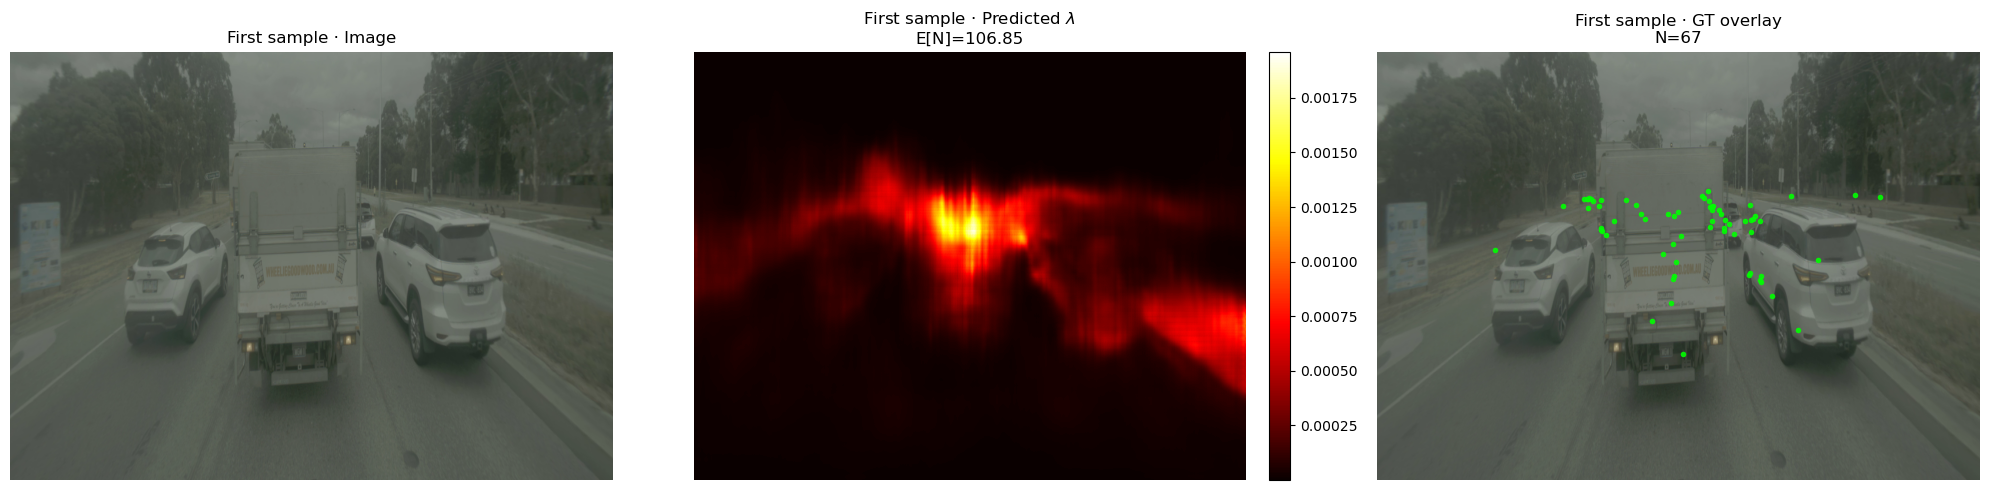

Initial blur with sigma=0.00 took 0.0036 seconds
Incremental blur with sigma_inc=3.16 (total sigma=3.16) took 0.0383 seconds
Incremental blur with sigma_inc=5.47 (total sigma=6.32) took 0.0525 seconds
Incremental blur with sigma_inc=7.06 (total sigma=9.47) took 0.0599 seconds
Incremental blur with sigma_inc=8.36 (total sigma=12.63) took 0.0594 seconds
Incremental blur with sigma_inc=9.47 (total sigma=15.79) took 0.0844 seconds
Incremental blur with sigma_inc=10.47 (total sigma=18.95) took 0.0881 seconds
Incremental blur with sigma_inc=11.39 (total sigma=22.11) took 0.0958 seconds
Incremental blur with sigma_inc=12.23 (total sigma=25.26) took 0.1094 seconds
Incremental blur with sigma_inc=13.02 (total sigma=28.42) took 0.1116 seconds
Incremental blur with sigma_inc=13.76 (total sigma=31.58) took 0.1193 seconds
Incremental blur with sigma_inc=14.47 (total sigma=34.74) took 0.1269 seconds
Incremental blur with sigma_inc=15.14 (total sigma=37.89) took 0.1358 seconds
Incremental blur with s

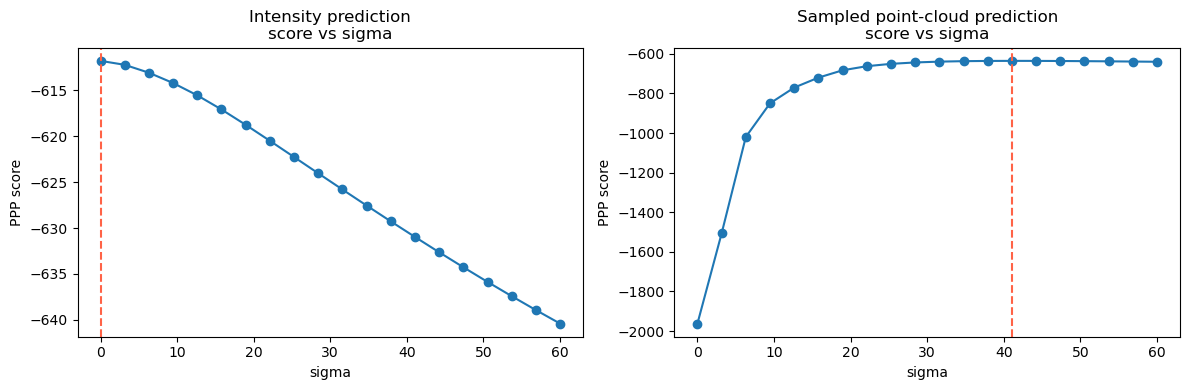

In [73]:
# ============================================================
# 7 · Quick Smoke Test on First Sample
# ============================================================

h5_path_0, key_0 = all_samples[0]
sample0 = load_h5_sample(h5_path_0, key_0)

img0 = sample0["img"]
pred_lambda0 = sample0["pred_lambda"]
gt_support0 = sample0["gt_support"]
ppp0 = sample0["ppp"]
meta0 = sample0["meta"]

print(f"Sample : {meta0['h5_file']} / {meta0['sample_key']}")
print(f"Shape  : {pred_lambda0.shape}")
print(f"E[N]   : {ppp0['expected_count']:.3f}")
print(f"GT N   : {ppp0['gt_count']}")

show_sample_triptych(img0, pred_lambda0, gt_support0, title_prefix="First sample · ")

res_int = optimize_sigma_for_intensity(pred_lambda0, gt_support0, sigma_grid=SIGMA_GRID)
print("\nIntensity-based prediction")
print("Best sigma :", res_int["best_sigma"])
print("Best score :", res_int["best_score"])

sampled_pc0, sampled_meta0 = sample_point_cloud_from_lambda(
    pred_lambda0,
    rng=np.random.default_rng(0),
    mode=POINT_SAMPLING_MODE,
    gt_count=ppp0["gt_count"],
)
res_pc = optimize_sigma_for_point_cloud(sampled_pc0, gt_support0, sigma_grid=SIGMA_GRID)
print("\nPoint-cloud prediction (one sampled realization)")
print("Sampling meta :", sampled_meta0)
print("Best sigma    :", res_pc["best_sigma"])
print("Best score    :", res_pc["best_score"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res_int["sigma_grid"], res_int["scores"], marker="o")
ax[0].axvline(res_int["best_sigma"], color="tomato", linestyle="--")
ax[0].set_title("Intensity prediction\nscore vs sigma")
ax[0].set_xlabel("sigma")
ax[0].set_ylabel("PPP score")

ax[1].plot(res_pc["sigma_grid"], res_pc["scores"], marker="o")
ax[1].axvline(res_pc["best_sigma"], color="tomato", linestyle="--")
ax[1].set_title("Sampled point-cloud prediction\nscore vs sigma")
ax[1].set_xlabel("sigma")
ax[1].set_ylabel("PPP score")

plt.tight_layout()
plt.show()

I.e. The two evaluation pipelines exhibit fundamentally different behavior because they operate on different representations of the same underlying predictive distribution. When the predicted intensity field is evaluated directly, it already provides a smooth and spatially coherent estimate of the underlying point process. In this case, Gaussian smoothing acts purely as a degradation mechanism: increasing the smoothing scale disperses mass away from the ground-truth locations, leading to a monotonic decrease in the log-likelihood score.

In contrast, when a point cloud is sampled from the same intensity via a Poisson process, the prediction becomes a sparse and noisy realization of the distribution. At small smoothing scales, this representation assigns negligible density to most ground-truth locations, resulting in very low likelihood values. Gaussianization therefore plays a fundamentally different role: it acts as a kernel density estimator that compensates for sampling sparsity and variance. As the smoothing scale increases, the reconstructed density becomes more stable and better aligned with the ground truth, until excessive smoothing again destroys spatial precision.

This leads to a crucial observation: the optimal smoothing scale is not an intrinsic property of the underlying distribution, but depends strongly on its representation. While the intensity-based prediction prefers minimal smoothing, the sampled point cloud requires substantial smoothing to recover a meaningful density estimate. Consequently, the proposed metric does not evaluate predictions in a representation-invariant manner, but rather measures the best achievable likelihood after optimal reconstruction of a continuous density from the given representation.

# Optimization based method

In [75]:
# ============================================================
# Newton-like sigma optimization:
# Safeguarded secant method in log-sigma space
# ============================================================

import numpy as np
import math


def _score_sigma_intensity(pred_lambda, gt_support, sigma):
    h = gaussianize_intensity(pred_lambda, sigma=float(sigma))
    return ppp_loglik_score(h, gt_support)


def _score_sigma_point_cloud(point_grid, gt_support, sigma):
    h = gaussianize_point_cloud(point_grid, sigma=float(sigma))
    return ppp_loglik_score(h, gt_support)


def _finite_diff_grad_logsigma(score_fn, u, eps=1e-2):
    """
    Numerical derivative of phi(u) = score_fn(exp(u))
    via central finite differences.
    """
    up = u + eps
    um = u - eps
    sp = score_fn(math.exp(up))
    sm = score_fn(math.exp(um))
    return (sp - sm) / (2.0 * eps)


def _safeguarded_secant_max_1d_logsigma(
    score_fn,
    sigma_min,
    sigma_max,
    u0=None,
    u1=None,
    grad_eps=1e-2,
    max_iter=20,
    tol_u=1e-3,
    tol_g=1e-4,
    verbose=False,
):
    """
    Maximize score_fn(sigma) over sigma in [sigma_min, sigma_max]
    by solving d/du score(exp(u)) = 0 with a safeguarded secant method.

    Returns
    -------
    dict with best_sigma, best_score, histories, status
    """
    if sigma_min <= 0 or sigma_max <= sigma_min:
        raise ValueError("Need 0 < sigma_min < sigma_max")

    uL = math.log(float(sigma_min))
    uR = math.log(float(sigma_max))

    # default initial points inside interval
    if u0 is None:
        u0 = uL + 0.30 * (uR - uL)
    if u1 is None:
        u1 = uL + 0.70 * (uR - uL)

    u0 = float(np.clip(u0, uL, uR))
    u1 = float(np.clip(u1, uL, uR))

    # boundary checks
    gL = _finite_diff_grad_logsigma(score_fn, uL, eps=grad_eps)
    gR = _finite_diff_grad_logsigma(score_fn, uR, eps=grad_eps)
    sL = score_fn(math.exp(uL))
    sR = score_fn(math.exp(uR))

    # if monotone on the whole interval, boundary optimum
    if gL <= 0 and gR <= 0:
        return {
            "best_sigma": float(math.exp(uL)),
            "best_score": float(sL),
            "sigma_history": np.array([math.exp(uL)], dtype=np.float64),
            "score_history": np.array([sL], dtype=np.float64),
            "grad_history": np.array([gL], dtype=np.float64),
            "status": "left_boundary_monotone",
        }
    if gL >= 0 and gR >= 0:
        return {
            "best_sigma": float(math.exp(uR)),
            "best_score": float(sR),
            "sigma_history": np.array([math.exp(uR)], dtype=np.float64),
            "score_history": np.array([sR], dtype=np.float64),
            "grad_history": np.array([gR], dtype=np.float64),
            "status": "right_boundary_monotone",
        }

    # We want a bracket with gradient sign change: g(left) > 0, g(right) < 0
    # If not, swap logic as needed
    if gL < 0 and gR > 0:
        # unusual orientation, but keep working
        pass

    g0 = _finite_diff_grad_logsigma(score_fn, u0, eps=grad_eps)
    g1 = _finite_diff_grad_logsigma(score_fn, u1, eps=grad_eps)
    s0 = score_fn(math.exp(u0))
    s1 = score_fn(math.exp(u1))

    u_hist = [u0, u1]
    sigma_hist = [math.exp(u0), math.exp(u1)]
    score_hist = [s0, s1]
    grad_hist = [g0, g1]

    # current best
    best_u = u0 if s0 >= s1 else u1
    best_s = max(s0, s1)

    for k in range(max_iter):
        denom = (g1 - g0)

        # secant step on gradient root
        if abs(denom) < 1e-12:
            u2 = 0.5 * (u0 + u1)
        else:
            u2 = u1 - g1 * (u1 - u0) / denom

        # safeguard: keep inside domain
        if (not np.isfinite(u2)) or (u2 <= uL) or (u2 >= uR):
            u2 = 0.5 * (u0 + u1)

        g2 = _finite_diff_grad_logsigma(score_fn, u2, eps=grad_eps)
        s2 = score_fn(math.exp(u2))

        u_hist.append(u2)
        sigma_hist.append(math.exp(u2))
        score_hist.append(s2)
        grad_hist.append(g2)

        if s2 > best_s:
            best_s = s2
            best_u = u2

        if verbose:
            print(
                f"iter={k:02d}  sigma={math.exp(u2):.6f}  "
                f"score={s2:.6f}  grad={g2:.6f}"
            )

        # stopping
        if abs(g2) < tol_g:
            break
        if abs(u2 - u1) < tol_u:
            break

        # keep a sign-changing pair if possible
        # want root of gradient, so opposite signs is good
        if g1 == 0:
            break
        elif g0 * g2 <= 0:
            u1, g1, s1 = u2, g2, s2
        else:
            u0, g0, s0 = u2, g2, s2

        # if pair collapsed or same sign, just keep last two secant iterates
        if np.sign(g0) == np.sign(g1):
            u0, g0, s0 = u1, g1, s1
            u1, g1, s1 = u2, g2, s2

    return {
        "best_sigma": float(math.exp(best_u)),
        "best_score": float(best_s),
        "sigma_history": np.asarray(sigma_hist, dtype=np.float64),
        "score_history": np.asarray(score_hist, dtype=np.float64),
        "grad_history": np.asarray(grad_hist, dtype=np.float64),
        "status": "ok",
    }


def optimize_sigma_for_intensity_secant(
    pred_lambda,
    gt_support,
    sigma_min=1.0,
    sigma_max=150.0,
    sigma_init0=None,
    sigma_init1=None,
    grad_eps=1e-2,
    max_iter=20,
    tol_u=1e-3,
    tol_g=1e-4,
    verbose=False,
):
    score_fn = lambda sigma: _score_sigma_intensity(pred_lambda, gt_support, sigma)
    u0 = None if sigma_init0 is None else math.log(float(sigma_init0))
    u1 = None if sigma_init1 is None else math.log(float(sigma_init1))
    return _safeguarded_secant_max_1d_logsigma(
        score_fn=score_fn,
        sigma_min=sigma_min,
        sigma_max=sigma_max,
        u0=u0,
        u1=u1,
        grad_eps=grad_eps,
        max_iter=max_iter,
        tol_u=tol_u,
        tol_g=tol_g,
        verbose=verbose,
    )


def optimize_sigma_for_point_cloud_secant(
    point_grid,
    gt_support,
    sigma_min=1.0,
    sigma_max=150.0,
    sigma_init0=None,
    sigma_init1=None,
    grad_eps=1e-2,
    max_iter=20,
    tol_u=1e-3,
    tol_g=1e-4,
    verbose=False,
):
    score_fn = lambda sigma: _score_sigma_point_cloud(point_grid, gt_support, sigma)
    u0 = None if sigma_init0 is None else math.log(float(sigma_init0))
    u1 = None if sigma_init1 is None else math.log(float(sigma_init1))
    return _safeguarded_secant_max_1d_logsigma(
        score_fn=score_fn,
        sigma_min=sigma_min,
        sigma_max=sigma_max,
        u0=u0,
        u1=u1,
        grad_eps=grad_eps,
        max_iter=max_iter,
        tol_u=tol_u,
        tol_g=tol_g,
        verbose=verbose,
    )

print("Loaded: optimize_sigma_for_intensity_secant, optimize_sigma_for_point_cloud_secant")

Loaded: optimize_sigma_for_intensity_secant, optimize_sigma_for_point_cloud_secant


In [76]:
res_int_sec = optimize_sigma_for_intensity_secant(
    pred_lambda0,
    gt_support0,
    sigma_min=1.0,
    sigma_max=150.0,
    sigma_init0=5.0,
    sigma_init1=40.0,
    verbose=True,
)

print(res_int_sec["best_sigma"], res_int_sec["best_score"])

1.0 -611.891239637617


In [77]:
res_pc_sec = optimize_sigma_for_point_cloud_secant(
    sampled_pc0,
    gt_support0,
    sigma_min=1.0,
    sigma_max=150.0,
    sigma_init0=10.0,
    sigma_init1=60.0,
    verbose=True,
)

print(res_pc_sec["best_sigma"], res_pc_sec["best_score"])

iter=00  sigma=48.879293  score=-637.581658  grad=-13.124022
iter=01  sigma=43.946517  score=-636.558937  grad=-5.772807
iter=02  sigma=41.997664  score=-636.376163  grad=-2.245082
iter=03  sigma=41.272138  score=-636.350166  grad=-0.743388
iter=04  sigma=41.035636  score=-636.347913  grad=-0.209975
iter=05  sigma=40.969156  score=-636.347720  grad=-0.044552
iter=06  sigma=40.955068  score=-636.347709  grad=0.000840
40.95506824579353 -636.3477088030878


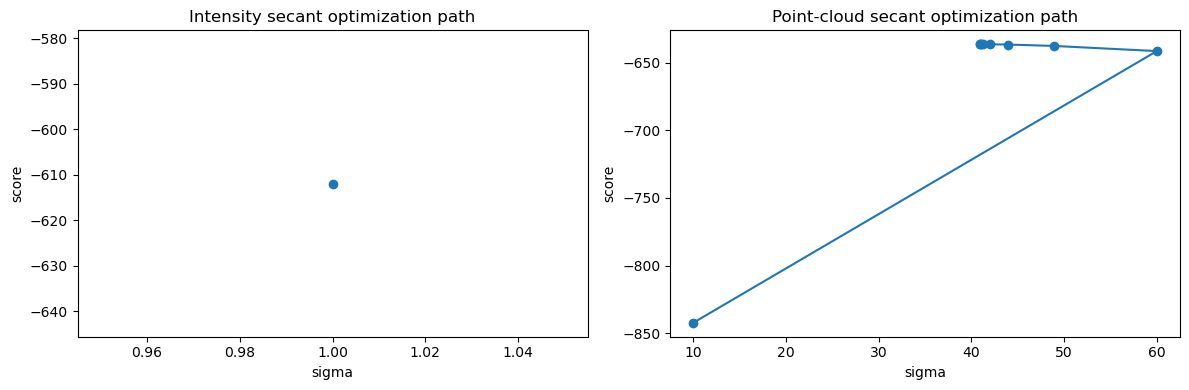

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(res_int_sec["sigma_history"], res_int_sec["score_history"], marker="o")
ax[0].set_title("Intensity secant optimization path")
ax[0].set_xlabel("sigma")
ax[0].set_ylabel("score")

ax[1].plot(res_pc_sec["sigma_history"], res_pc_sec["score_history"], marker="o")
ax[1].set_title("Point-cloud secant optimization path")
ax[1].set_xlabel("sigma")
ax[1].set_ylabel("score")

plt.tight_layout()
plt.show()

# 8 — Interactive single-image browser

In [ ]:
# ============================================================
# 8 · Interactive Single-Image Browser
# ============================================================

selected_samples = []   # list of (basename(h5_path), sample_key)

n = len(all_samples)

slider = widgets.IntSlider(
    value=0, min=0, max=n - 1, step=1,
    description="Sample:",
    continuous_update=False,
    layout=widgets.Layout(width="650px"),
)

btn_add = widgets.ToggleButton(
    value=False,
    description="☆ Add to selection",
    button_style="",
    layout=widgets.Layout(width="180px"),
)

sigma_dropdown = widgets.Dropdown(
    options=SIGMA_GRID,
    value=SIGMA_GRID[0],
    description="Plot σ:",
    layout=widgets.Layout(width="220px"),
)

rng_seed_box = widgets.IntText(
    value=0,
    description="Sample seed:",
    layout=widgets.Layout(width="220px"),
)

plot_out = widgets.Output()
select_out = widgets.Output()


def _current_entry(idx):
    h5_path, key = all_samples[idx]
    return (os.path.basename(h5_path), key)


def _update_btn(idx):
    entry = _current_entry(idx)
    in_sel = entry in selected_samples
    btn_add.value = in_sel
    btn_add.description = "★ In selection" if in_sel else "☆ Add to selection"
    btn_add.button_style = "success" if in_sel else ""


def _render_browser(idx, sigma_plot, sample_seed):
    h5_path, key = all_samples[idx]
    s = load_h5_sample(h5_path, key)

    img = s["img"]
    pred_lambda = s["pred_lambda"]
    gt_support = s["gt_support"]
    ppp = s["ppp"]
    meta = s["meta"]

    res_int = optimize_sigma_for_intensity(pred_lambda, gt_support, sigma_grid=SIGMA_GRID)

    sampled_pc, sampled_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(sample_seed),
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )
    res_pc = optimize_sigma_for_point_cloud(sampled_pc, gt_support, sigma_grid=SIGMA_GRID)

    g_int_plot = gaussianize_intensity(pred_lambda, sigma=sigma_plot)
    g_pc_plot = gaussianize_point_cloud(sampled_pc, sigma=sigma_plot)

    gt_ys, gt_xs = np.where(gt_support > 0)
    pc_ys, pc_xs = np.where(sampled_pc > 0)

    with plot_out:
        clear_output(wait=True)

        print(f"Sample         : {meta['h5_file']} / {meta['sample_key']}")
        print(f"E[N]           : {ppp['expected_count']:.3f}")
        print(f"GT count       : {ppp['gt_count']}")
        print(f"Point sample   : {sampled_meta}")
        print(f"Best intensity : score={res_int['best_score']:.6f}, sigma={res_int['best_sigma']}")
        print(f"Best pointcloud: score={res_pc['best_score']:.6f}, sigma={res_pc['best_sigma']}")

        fig, axes = plt.subplots(2, 3, figsize=(18, 9))

        axes[0, 0].imshow(img, aspect="auto")
        axes[0, 0].set_title("Image")
        axes[0, 0].axis("off")

        im1 = axes[0, 1].imshow(pred_lambda, cmap="hot", aspect="auto")
        axes[0, 1].set_title(rf"Predicted $\lambda$" + f"\nE[N]={pred_lambda.sum():.2f}")
        axes[0, 1].axis("off")
        plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

        axes[0, 2].imshow(img, aspect="auto")
        axes[0, 2].scatter(gt_xs, gt_ys, s=GT_DOT_SIZE, c="lime", linewidths=0)
        axes[0, 2].set_title(f"GT overlay\nN={int(gt_support.sum())}")
        axes[0, 2].axis("off")

        im2 = axes[1, 0].imshow(g_int_plot, cmap="hot", aspect="auto")
        axes[1, 0].set_title(f"Gaussianized intensity\nσ={sigma_plot}")
        axes[1, 0].axis("off")
        plt.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

        axes[1, 1].imshow(img, aspect="auto")
        axes[1, 1].scatter(pc_xs, pc_ys, s=GT_DOT_SIZE, c="deepskyblue", linewidths=0)
        axes[1, 1].set_title(f"One sampled point cloud\nN={int(sampled_pc.sum())}")
        axes[1, 1].axis("off")

        im3 = axes[1, 2].imshow(g_pc_plot, cmap="hot", aspect="auto")
        axes[1, 2].set_title(f"Gaussianized sampled point cloud\nσ={sigma_plot}")
        axes[1, 2].axis("off")
        plt.colorbar(im3, ax=axes[1, 2], fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()

        fig2, ax2 = plt.subplots(1, 2, figsize=(12, 4))

        ax2[0].plot(res_int["sigma_grid"], res_int["scores"], marker="o")
        ax2[0].axvline(res_int["best_sigma"], color="tomato", linestyle="--")
        ax2[0].set_title("Intensity prediction\nscore vs sigma")
        ax2[0].set_xlabel("sigma")
        ax2[0].set_ylabel("PPP score")

        ax2[1].plot(res_pc["sigma_grid"], res_pc["scores"], marker="o")
        ax2[1].axvline(res_pc["best_sigma"], color="tomato", linestyle="--")
        ax2[1].set_title("Sampled point-cloud prediction\nscore vs sigma")
        ax2[1].set_xlabel("sigma")
        ax2[1].set_ylabel("PPP score")

        plt.tight_layout()
        plt.show()

    with select_out:
        clear_output(wait=True)
        print(f"Selected samples: {len(selected_samples)}")
        for i, entry in enumerate(selected_samples, 1):
            print(f"  [{i:>2}] {entry[0]} / {entry[1]}")


def _on_slider_change(change):
    if change["name"] == "value":
        _update_btn(change["new"])
        _render_browser(slider.value, sigma_dropdown.value, rng_seed_box.value)


def _on_sigma_change(change):
    if change["name"] == "value":
        _render_browser(slider.value, sigma_dropdown.value, rng_seed_box.value)


def _on_seed_change(change):
    if change["name"] == "value":
        _render_browser(slider.value, sigma_dropdown.value, rng_seed_box.value)


def _on_add_toggle(change):
    entry = _current_entry(slider.value)
    if change["new"]:
        if entry not in selected_samples:
            selected_samples.append(entry)
    else:
        if entry in selected_samples:
            selected_samples.remove(entry)
    _update_btn(slider.value)
    _render_browser(slider.value, sigma_dropdown.value, rng_seed_box.value)


slider.observe(_on_slider_change)
sigma_dropdown.observe(_on_sigma_change)
rng_seed_box.observe(_on_seed_change)
btn_add.observe(_on_add_toggle, names="value")

controls = widgets.HBox([slider, btn_add])
controls2 = widgets.HBox([sigma_dropdown, rng_seed_box])

display(controls)
display(controls2)
display(plot_out)
display(select_out)

_update_btn(slider.value)
_render_browser(slider.value, sigma_dropdown.value, rng_seed_box.value)

# 9 — Print selected samples

In [ ]:
# ============================================================
# 9 · Print Final Selection
# ============================================================

print(f"selected_samples = {selected_samples!r}")

# 10 — Single-image evaluation for selected samples

In [ ]:
# ============================================================
# 10 · Single-Image Evaluation for Selected Samples
# ============================================================

assert selected_samples, "No samples selected in the browser."

single_eval_rows = []

for i, (h5_file_base, sample_key) in enumerate(selected_samples, 1):
    h5_path = None
    for p in h5_files:
        if os.path.basename(p) == h5_file_base:
            h5_path = p
            break
    assert h5_path is not None, f"Could not find H5 path for {h5_file_base}"

    s = load_h5_sample(h5_path, sample_key)
    img = s["img"]
    pred_lambda = s["pred_lambda"]
    gt_support = s["gt_support"]
    ppp = s["ppp"]
    meta = s["meta"]

    res_int = optimize_sigma_for_intensity(pred_lambda, gt_support, sigma_grid=SIGMA_GRID)

    sampled_pc, sampled_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=np.random.default_rng(i),
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )
    res_pc = optimize_sigma_for_point_cloud(sampled_pc, gt_support, sigma_grid=SIGMA_GRID)

    single_eval_rows.append({
        "sample_idx": i,
        "h5_file": meta["h5_file"],
        "sample_key": meta["sample_key"],
        "expected_count": ppp["expected_count"],
        "gt_count": ppp["gt_count"],
        "int_best_sigma": res_int["best_sigma"],
        "int_best_score": res_int["best_score"],
        "pc_best_sigma": res_pc["best_sigma"],
        "pc_best_score": res_pc["best_score"],
        "pc_binary_count": int(sampled_pc.sum()),
        "pc_sampling_mode": sampled_meta["mode"],
    })

    print(f"\n{'='*80}")
    print(f"[{i}/{len(selected_samples)}] {meta['h5_file']} / {meta['sample_key']}")
    print(f"Intensity prediction: best score = {res_int['best_score']:.6f}, sigma = {res_int['best_sigma']}")
    print(f"Point-cloud sample : best score = {res_pc['best_score']:.6f}, sigma = {res_pc['best_sigma']}")

    gt_ys, gt_xs = np.where(gt_support > 0)
    pc_ys, pc_xs = np.where(sampled_pc > 0)

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))

    axes[0, 0].imshow(img, aspect="auto")
    axes[0, 0].set_title("Image")
    axes[0, 0].axis("off")

    im0 = axes[0, 1].imshow(pred_lambda, cmap="hot", aspect="auto")
    axes[0, 1].set_title(rf"Predicted $\lambda$")
    axes[0, 1].axis("off")
    plt.colorbar(im0, ax=axes[0, 1], fraction=0.046, pad=0.04)

    axes[0, 2].imshow(img, aspect="auto")
    axes[0, 2].scatter(gt_xs, gt_ys, s=GT_DOT_SIZE, c="lime", linewidths=0)
    axes[0, 2].set_title("GT overlay")
    axes[0, 2].axis("off")

    best_g_int = gaussianize_intensity(pred_lambda, sigma=res_int["best_sigma"])
    im1 = axes[1, 0].imshow(best_g_int, cmap="hot", aspect="auto")
    axes[1, 0].set_title(f"Best gaussianized intensity\nσ={res_int['best_sigma']}")
    axes[1, 0].axis("off")
    plt.colorbar(im1, ax=axes[1, 0], fraction=0.046, pad=0.04)

    axes[1, 1].imshow(img, aspect="auto")
    axes[1, 1].scatter(pc_xs, pc_ys, s=GT_DOT_SIZE, c="deepskyblue", linewidths=0)
    axes[1, 1].set_title(f"One sampled point cloud\nN={int(sampled_pc.sum())}")
    axes[1, 1].axis("off")

    best_g_pc = gaussianize_point_cloud(sampled_pc, sigma=res_pc["best_sigma"])
    im2 = axes[1, 2].imshow(best_g_pc, cmap="hot", aspect="auto")
    axes[1, 2].set_title(f"Best gaussianized point cloud\nσ={res_pc['best_sigma']}")
    axes[1, 2].axis("off")
    plt.colorbar(im2, ax=axes[1, 2], fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()

df_single_eval = pd.DataFrame(single_eval_rows)
display(df_single_eval)

# 11 — One sampled point-cloud per image over a list

In [ ]:
# ============================================================
# 11 · One Sample per Image over a List
# ============================================================

# Use the browser selection if available; otherwise fall back to first K images.
USE_SELECTED_FOR_LIST_EVAL = True
FALLBACK_N_IMAGES = 20
LIST_EVAL_RNG_SEED = 123

if USE_SELECTED_FOR_LIST_EVAL and selected_samples:
    eval_entries = []
    for h5_file_base, sample_key in selected_samples:
        for p in h5_files:
            if os.path.basename(p) == h5_file_base:
                eval_entries.append((p, sample_key))
                break
else:
    eval_entries = all_samples[:FALLBACK_N_IMAGES]

print(f"Number of images for list evaluation: {len(eval_entries)}")

rows = []
rng_master = np.random.default_rng(LIST_EVAL_RNG_SEED)

for idx, (h5_path, sample_key) in enumerate(eval_entries, 1):
    s = load_h5_sample(h5_path, sample_key)
    pred_lambda = s["pred_lambda"]
    gt_support = s["gt_support"]
    ppp = s["ppp"]
    meta = s["meta"]

    sample_rng = np.random.default_rng(int(rng_master.integers(0, 2**32)))
    sampled_pc, sampled_meta = sample_point_cloud_from_lambda(
        pred_lambda,
        rng=sample_rng,
        mode=POINT_SAMPLING_MODE,
        gt_count=ppp["gt_count"],
    )

    res_int = optimize_sigma_for_intensity(pred_lambda, gt_support, sigma_grid=SIGMA_GRID)
    res_pc = optimize_sigma_for_point_cloud(sampled_pc, gt_support, sigma_grid=SIGMA_GRID)

    rows.append({
        "idx": idx,
        "h5_file": meta["h5_file"],
        "sample_key": meta["sample_key"],
        "expected_count": ppp["expected_count"],
        "gt_count": ppp["gt_count"],
        "int_best_sigma": res_int["best_sigma"],
        "int_best_score": res_int["best_score"],
        "pc_best_sigma": res_pc["best_sigma"],
        "pc_best_score": res_pc["best_score"],
        "pc_binary_count": int(sampled_pc.sum()),
    })

    print(
        f"[{idx:>3}/{len(eval_entries)}] "
        f"{meta['sample_key']} | "
        f"int={res_int['best_score']:.6f} @ {res_int['best_sigma']} | "
        f"pc={res_pc['best_score']:.6f} @ {res_pc['best_sigma']}"
    )

df_list_eval = pd.DataFrame(rows)
display(df_list_eval)

print("\nSummary:")
print("Intensity mean best score :", df_list_eval["int_best_score"].mean())
print("PointCloud mean best score:", df_list_eval["pc_best_score"].mean())
print("Mean difference int-pc    :", (df_list_eval["int_best_score"] - df_list_eval["pc_best_score"]).mean())

# 12 — Plots for one-sample-per-image evaluation

In [ ]:
# ============================================================
# 12 · Plots for One-Sample-per-Image Evaluation
# ============================================================

assert "df_list_eval" in globals() and len(df_list_eval) > 0, "Run the previous cell first."

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].hist(df_list_eval["int_best_score"], bins=20, alpha=0.75, label="Intensity")
axes[0].hist(df_list_eval["pc_best_score"], bins=20, alpha=0.75, label="Point cloud sample")
axes[0].set_title("Best score distribution")
axes[0].set_xlabel("best PPP score")
axes[0].legend()

axes[1].scatter(df_list_eval["gt_count"], df_list_eval["int_best_score"], label="Intensity", alpha=0.8)
axes[1].scatter(df_list_eval["gt_count"], df_list_eval["pc_best_score"], label="Point cloud sample", alpha=0.8)
axes[1].set_title("Score vs GT count")
axes[1].set_xlabel("GT count")
axes[1].set_ylabel("best PPP score")
axes[1].legend()

diff = df_list_eval["int_best_score"] - df_list_eval["pc_best_score"]
axes[2].hist(diff, bins=20, alpha=0.85)
axes[2].axvline(diff.mean(), color="tomato", linestyle="--", label=f"mean={diff.mean():.4f}")
axes[2].set_title("Intensity minus point-cloud score")
axes[2].set_xlabel("score difference")
axes[2].legend()

plt.tight_layout()
plt.show()

# 13 — Model comparison over N images

In [ ]:
# ============================================================
# 13 · Model Comparison over N Images
# ============================================================

N_IMAGES_COMPARE = 20      # set None for all
COMPARE_RNG_SEED = 2026

model_rows = []

for model_name, h5_dir in H5_DIRS.items():
    if not os.path.isdir(h5_dir):
        print(f"[SKIP] {model_name} – directory not found")
        continue

    model_h5_files = sorted(glob.glob(os.path.join(h5_dir, "rank*.h5")))
    model_samples = list_h5_samples(model_h5_files)

    if N_IMAGES_COMPARE is not None:
        model_samples = model_samples[:N_IMAGES_COMPARE]

    print(f"\n{'='*90}")
    print(f"Model: {model_name}")
    print(f"Images: {len(model_samples)}")

    rng_master = np.random.default_rng(COMPARE_RNG_SEED)

    for idx, (h5_path, sample_key) in enumerate(model_samples, 1):
        s = load_h5_sample(h5_path, sample_key)
        pred_lambda = s["pred_lambda"]
        gt_support = s["gt_support"]
        ppp = s["ppp"]
        meta = s["meta"]

        res_int = optimize_sigma_for_intensity(pred_lambda, gt_support, sigma_grid=SIGMA_GRID)

        sample_rng = np.random.default_rng(int(rng_master.integers(0, 2**32)))
        sampled_pc, sampled_meta = sample_point_cloud_from_lambda(
            pred_lambda,
            rng=sample_rng,
            mode=POINT_SAMPLING_MODE,
            gt_count=ppp["gt_count"],
        )
        res_pc = optimize_sigma_for_point_cloud(sampled_pc, gt_support, sigma_grid=SIGMA_GRID)

        model_rows.append({
            "model_name": model_name,
            "sample_idx": idx,
            "sample_key": meta["sample_key"],
            "expected_count": ppp["expected_count"],
            "gt_count": ppp["gt_count"],
            "int_best_sigma": res_int["best_sigma"],
            "int_best_score": res_int["best_score"],
            "pc_best_sigma": res_pc["best_sigma"],
            "pc_best_score": res_pc["best_score"],
            "pc_binary_count": int(sampled_pc.sum()),
        })

        print(
            f"[{idx:>3}/{len(model_samples)}] "
            f"{meta['sample_key']} | "
            f"int={res_int['best_score']:.6f} | "
            f"pc={res_pc['best_score']:.6f}"
        )

df_model_compare = pd.DataFrame(model_rows)
display(df_model_compare.head())
print(f"\nTotal rows: {len(df_model_compare)}")

# 14 — Summary table for model comparison

In [ ]:
# ============================================================
# 14 · Summary Table for Model Comparison
# ============================================================

assert "df_model_compare" in globals() and len(df_model_compare) > 0, "Run the previous cell first."

summary = (
    df_model_compare
    .groupby("model_name")
    .agg(
        n_images=("sample_key", "count"),
        int_mean=("int_best_score", "mean"),
        int_std=("int_best_score", "std"),
        int_min=("int_best_score", "min"),
        int_max=("int_best_score", "max"),
        pc_mean=("pc_best_score", "mean"),
        pc_std=("pc_best_score", "std"),
        pc_min=("pc_best_score", "min"),
        pc_max=("pc_best_score", "max"),
    )
    .reset_index()
)

summary["int_rank"] = summary["int_mean"].rank(ascending=False, method="dense").astype(int)
summary["pc_rank"] = summary["pc_mean"].rank(ascending=False, method="dense").astype(int)
summary["mean_gap_int_minus_pc"] = summary["int_mean"] - summary["pc_mean"]

summary = summary.sort_values("int_mean", ascending=False).reset_index(drop=True)
display(summary)

# 15 — Model comparison plots

In [ ]:
# ============================================================
# 15 · Model Comparison Plots
# ============================================================

assert "summary" in globals() and len(summary) > 0, "Run the previous cell first."

names = summary["model_name"].tolist()
x = np.arange(len(names))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].bar(x, summary["int_mean"])
axes[0].set_xticks(x)
axes[0].set_xticklabels(names, rotation=25, ha="right")
axes[0].set_title("Model comparison\nIntensity-based metric")
axes[0].set_ylabel("mean best PPP score")

axes[1].bar(x, summary["pc_mean"])
axes[1].set_xticks(x)
axes[1].set_xticklabels(names, rotation=25, ha="right")
axes[1].set_title("Model comparison\nOne sampled point-cloud per image")
axes[1].set_ylabel("mean best PPP score")

axes[2].bar(x, summary["mean_gap_int_minus_pc"])
axes[2].axhline(0.0, color="black", linewidth=1)
axes[2].set_xticks(x)
axes[2].set_xticklabels(names, rotation=25, ha="right")
axes[2].set_title("Intensity mean minus point-cloud mean")
axes[2].set_ylabel("score gap")

plt.tight_layout()
plt.show()